In [9]:
#https://www.kaggle.com/datasets/thomasnibb/image-classification-covid19-xray
import matplotlib.pyplot as plt
import matplotlib.image as mpimg # format pyplots
#from keras.preprocessing.image import ImageDataGenerator # for data augmentation
from keras.models import Sequential # to define the model using CNN
from keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from keras.layers import Activation, Dropout, Flatten, Dense

import os #work with file structure
import cv2 # opencv for reading images
from PIL import Image # Python Imaging Library provides support for opening, manipulating, and saving many different image file formats
import numpy as np

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
image_directory = '/content/drive/MyDrive/Colab Notebooks/Data/covid-19 data/'
SIZE = 150 # to bring all images to same size
dataset = []  # create an empty list and will be populated as we read images
label = []  #Place holders to define add labels. We will add 0 to all covid images and 1 to normal images.

In [12]:
covid_images = os.listdir(image_directory + 'Covid19/')# specify the path of image folder
for i, image_name in enumerate(covid_images):    #Remember enumerate method adds a counter and returns the enumerate object

    if (image_name.split('.')[1] == 'jpg'): #check extension is jpg
       image = cv2.imread(image_directory + 'Covid19/' + image_name) #read the images using opencv
       image = Image.fromarray(image, 'RGB')
       image = image.resize((SIZE, SIZE))
       dataset.append(np.array(image))# After resizing, image gets appended in the empty list
       label.append(1)
#Iterate through all images in normal folder, resize
#Then save into the same numpy array 'dataset' but with label 1

normal_images = os.listdir(image_directory + 'Normal/')
for i, image_name in enumerate(normal_images):
    if (image_name.split('.')[1] == 'jpg'):
        image = cv2.imread(image_directory + 'Normal/' + image_name)
        image = Image.fromarray(image, 'RGB') #convert to PIL image for resizing
        image = image.resize((SIZE, SIZE))
        dataset.append(np.array(image))
        label.append(0)

dataset = np.array(dataset)
label = np.array(label)

/tmp/ipykernel_509/2043541226.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(image, 'RGB')
/tmp/ipykernel_509/2043541226.py:17: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(image, 'RGB') #convert to PIL image for resizing


In [13]:
print(dataset.shape)
print(label.shape)

(60, 150, 150, 3)
(60,)


Label for this image is:  0


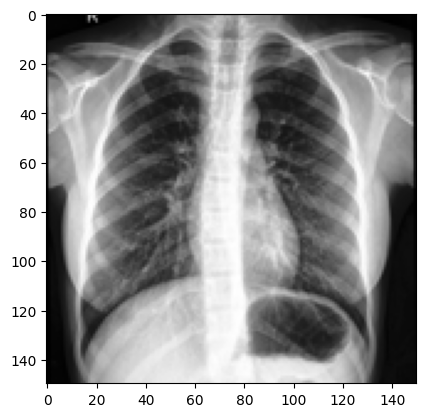

In [14]:
#Sanity check, view few mages
import random
import numpy as np
image_number = random.randint(0, len(dataset)-1)  # generate random integer and use that number to plot and label
plt.imshow(np.reshape(dataset[image_number], (150, 150, 3)))
print("Label for this image is: ", label[image_number])


In [15]:
from sklearn.model_selection import train_test_split
#from keras.utils import to_categorical

X_train, X_test, y_train, y_test = train_test_split(dataset, label, test_size = 0.20, random_state = 0)

In [16]:
print(dataset.shape)
print(label.shape)

(60, 150, 150, 3)
(60,)


In [17]:
#from keras.utils import normalize
#X_train = normalize(X_train, axis=1)
#X_test = normalize(X_test, axis=1)
X_train = X_train / 255. # as 8 bit images values range from 0-255
X_test = X_test / 255. #easiest way to scaling

In [18]:
###2 conv and pool layers. with some normalization and drops in between.

INPUT_SHAPE = (SIZE, SIZE, 3)   #change to (SIZE, SIZE, 3)
model = Sequential()
model.add(Conv2D(32, (3, 3), input_shape=INPUT_SHAPE)) # create convolution layers with 3*3 kernel  -they apply convolution filters on images and create features
model.add(Activation('relu')) # Rectified Linear Unit
model.add(MaxPooling2D(pool_size=(2, 2)))#calculates the maximum value for patches of a feature map

model.add(Conv2D(32, (3, 3), kernel_initializer = 'he_uniform'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), kernel_initializer = 'he_uniform'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten()) #Flattening convert 2D array  to 1D vector

model.add(Dense(64)) # Dense Layer with 64 neurons
model.add(Activation('relu'))
model.add(Dropout(0.5)) # 50% of output is dropped to avoid overfitting

model.add(Dense(1))# Binary classification so 1 input
model.add(Activation('sigmoid'))
#Do not use softmax for binary classification
#Softmax is useful for mutually exclusive classes, either cat or dog but not both.
#Also, softmax outputs all add to 1. So good for multi class problems where each
#class is given a probability and all add to 1. Highest one wins.

#Sigmoid outputs probability. Can be used for non-mutually exclusive problems.
#But, also good for binary mutually exclusive (cat or not cat).

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:

model.compile(loss='binary_crossentropy',        # compiling the model with loss function
              optimizer='rmsprop',             #also try adam /stochastic gradient
              metrics=['accuracy'])                 # follow metrics while training

print(model.summary())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 148, 148, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 72, 72, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 34, 34, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,183,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,212,513 (4.63 MB)

 Trainable params: 1,212,513 (4.63 MB)

 Non-trainable params: 0 (0.00 B)

None


In [20]:
history = model.fit(X_train,
                         y_train,
                         batch_size = 16, # Total images as input for training
                         verbose = 1,
                         epochs = 5, # no. of times the full datset is seen
                         validation_data=(X_test,y_test),
                         shuffle = False
                     )

Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 629ms/step - accuracy: 0.5417 - loss: 2.1395 - val_accuracy: 0.4167 - val_loss: 0.6840
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 464ms/step - accuracy: 0.6458 - loss: 0.6582 - val_accuracy: 0.7500 - val_loss: 0.6420
Epoch 3/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 641ms/step - accuracy: 0.6042 - loss: 0.6356 - val_accuracy: 0.8333 - val_loss: 0.5932
Epoch 4/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 815ms/step - accuracy: 0.6458 - loss: 0.6207 - val_accuracy: 0.4167 - val_loss: 0.6167
Epoch 5/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 770ms/step - accuracy: 0.7917 - loss: 0.4733 - val_accuracy: 1.0000 - val_loss: 0.4470


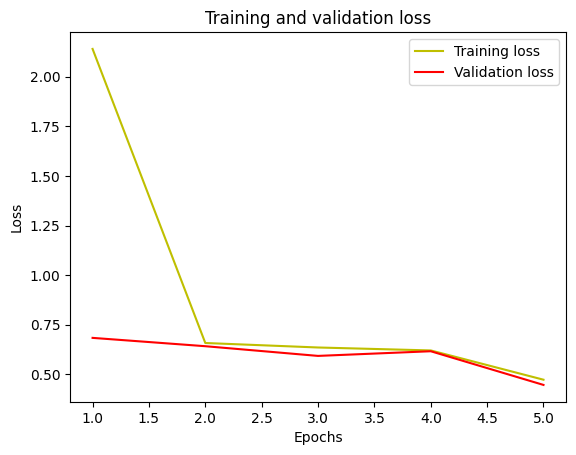

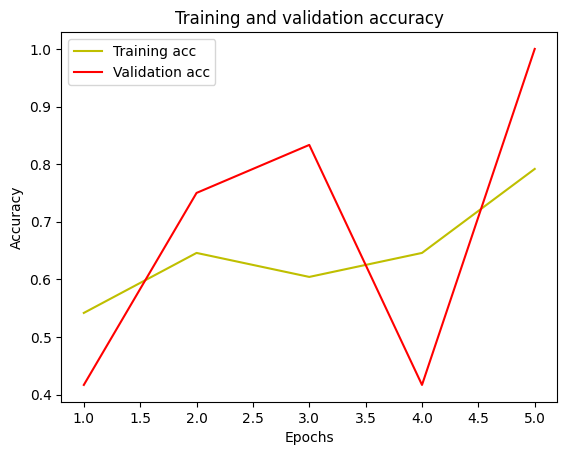

In [21]:
#plot the training and validation accuracy and loss at each epoch
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
The prediction for this image is:  [[0.40771574]]
The actual label for this image is:  0


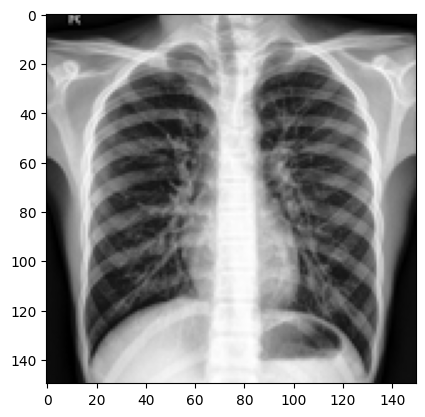

In [22]:
#Test the model on single images
n = random.randint(0, len(X_test)-1)
img = X_test[n]
plt.imshow(img)
input_img = np.expand_dims(img, axis=0) #Expand dims so the input is (num images, x, y, c)
print("The prediction for this image is: ", model.predict(input_img))
print("The actual label for this image is: ", y_test[n])

In [23]:
#Instead of checking for each image, we can evaluate the model on all test data
#for accuracy
################################################################

_, acc = model.evaluate(X_test, y_test)
print("Accuracy = ", (acc * 100.0), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 1.0000 - loss: 0.4470
Accuracy =  100.0 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step


<Axes: >

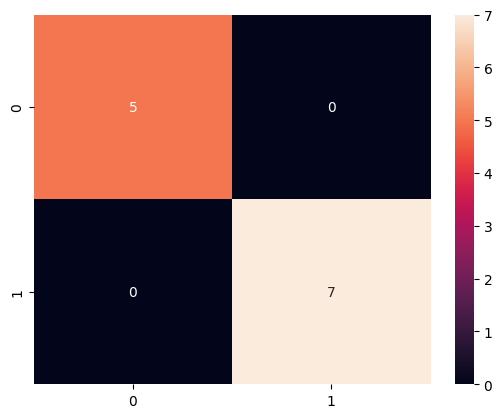

In [24]:

#How do we know how it is doing for infected vs uninfected?
################################################################

#Confusion matrix
#We compare labels and plot them based on correct or wrong predictions.
#Since sigmoid outputs probabilities we need to apply threshold to convert to label.

mythreshold=0.5
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = (model.predict(X_test)>= mythreshold).astype(int)
cm=confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True)

#Check the confusion matrix for various thresholds. Which one is good?
#Need to balance positive, negative, false positive and false negative.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step


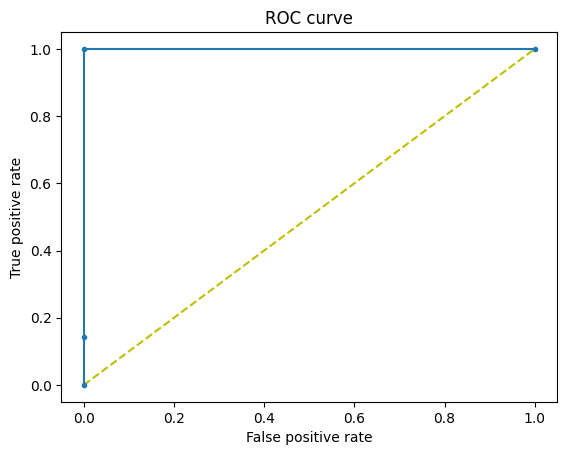

In [25]:
#ROC can help identify the right threshold.
"""
Receiver Operating Characteristic (ROC) Curve is a plot that helps us
visualize the performance of a binary classifier when the threshold is varied.
"""
#ROC
from sklearn.metrics import roc_curve
y_preds = model.predict(X_test).ravel()

fpr, tpr, thresholds = roc_curve(y_test, y_preds)
plt.figure(1)
plt.plot([0, 1], [0, 1], 'y--')
plt.plot(fpr, tpr, marker='.')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.show()


In [26]:
"""
#One way to find the best threshold once we calculate the true positive
and false positive rates is ...
The optimal cut off point would be where “true positive rate” is high
and the “false positive rate” is low.
Based on this logic let us find the threshold where tpr-(1-fpr) is zero (or close to 0)
"""
import pandas as pd
i = np.arange(len(tpr))
roc = pd.DataFrame({'tf' : pd.Series(tpr-(1-fpr), index=i), 'thresholds' : pd.Series(thresholds, index=i)})
ideal_roc_thresh = roc.iloc[(roc.tf-0).abs().argsort()[:1]]  #Locate the point where the value is close to 0
print("Ideal threshold is: ", ideal_roc_thresh['thresholds'])

Ideal threshold is:  2    0.676534
Name: thresholds, dtype: float32


In [27]:
#Now use this threshold value in the confusion matrix to visualize the balance
#between tp, fp, fp, and fn


#AUC
#Area under the curve (AUC) for ROC plot can be used to understand hpw well a classifier
#is performing.
#% chance that the model can distinguish between positive and negative classes.

from sklearn.metrics import auc
auc_value = auc(fpr, tpr)
print("Area under curve, AUC = ", auc_value)

Area under curve, AUC =  1.0
